In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
import geopandas as gpd
import sys
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENTS
from Functions import *

sys.path.insert(1, '../RandomForest')
from PrepDataFunctions import *

## ------------------------------------------------------------ ###
### Get rainfall events
    And add extra variables
## ------------------------------------------------------------ ###

In [21]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]
df =df[df['start_year']>1990]

## ------------------------------------------------------------ ###
### Get spatial data and add regional geometries to rainfall data
## ------------------------------------------------------------ ###

In [22]:
df  = add_geometries(df, CATCHMENTS)

## ------------------------------------------------------------ ###
### Add column defining which of 3 temporal periods an event is within
## ------------------------------------------------------------ ###

In [23]:
conditions = [df["start_year"].between(1990, 2020),df["start_year"].between(2020, 2050),
    df["start_year"].between(2050, 2080),]
periods = ["1990–2020", "2020–2050", "2050–2080"]

df["period"] = np.select(conditions, periods, default=None)

In [20]:
# df = df[df['peak_share']<0.8].copy()
# print(len(df))
# df = df[df['modality'] =='unimodal']
# print(len(df))

## ------------------------------------------------------------ ###
### Add column defining intensity bins
## ------------------------------------------------------------ ###

In [30]:
INT_BINS = [30, 35, 40, 45, 50, 60, 70, np.inf]
INT_LABELS = [f"{INT_BINS[i]}–{INT_BINS[i+1]}" for i in range(len(INT_BINS)-2)] + ["100+"]
df["intensity_bin"] = pd.cut(df["max_precip"], bins=INT_BINS, labels=INT_LABELS,
                                                 include_lowest=True)

LOADING_BINS = [0, 20, 40, 60, 80, 100]
LOADING_LABELS = [f"{LOADING_BINS[i]}–{LOADING_BINS[i+1]}" for i in range(len(LOADING_BINS)-1)] 
df["loading_bin"] = pd.cut(df["d50_n"], bins=LOADING_BINS, labels=LOADING_LABELS, 
                                               include_lowest=True)

PEAK_SHARE_BINS = [0, 0.20, 0.40, 0.60, 0.80, 1]
PEAK_SHARE_LABELS = [f"{PEAK_SHARE_BINS[i]}–{PEAK_SHARE_BINS[i+1]}" for i in range(len(PEAK_SHARE_BINS)-1)] 
df["peak_share_bin"] = pd.cut(df["peak_share"], bins=PEAK_SHARE_BINS, labels=PEAK_SHARE_LABELS, 
                                               include_lowest=True)

df["peak_class"] = pd.cut(df["peak_share"], [0, 0.5, 0.8, 1.0], 
                                              labels=["spread", "mixed", "peak-dominated"], include_lowest=True)

### Plots of the mean flooded area for events of different intensities

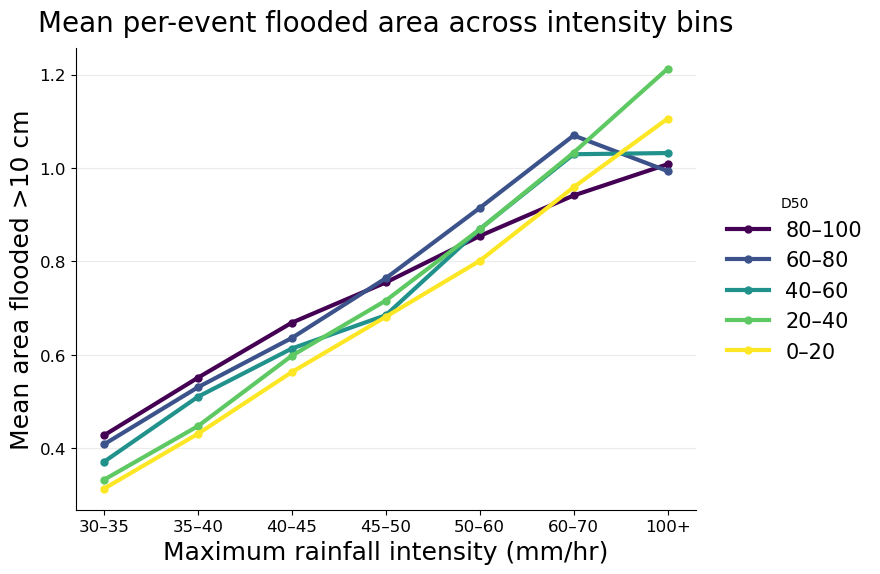

In [25]:
summary = (df.groupby(["loading_bin", "intensity_bin"], observed=True)["10cm_area"].mean().unstack())

colors = plt.cm.viridis(np.linspace(0, 1, 5))

fig, ax = plt.subplots(figsize=(8, 6))
for region, color in zip(reversed(loading_labels), colors):
    ax.plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)", fontsize=18)
ax.set_ylabel("Mean area flooded >10 cm", fontsize=18)
ax.set_title("Mean per-event flooded area across intensity bins",
             fontsize=20, pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="D50",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15);

In [33]:
# summary = (df.groupby(["peak_class", "intensity_bin"], observed=True)["10cm_area"].mean().unstack())

# colors = plt.cm.viridis(np.linspace(0, 1, 3))

# fig, ax = plt.subplots(figsize=(8, 6))

# # -------------------------
# # LEFT: rainfall plot
# # -------------------------

# for region, color in zip(reversed(["spread", "mixed", "peak-dominated"]), colors):
#     ax.plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

# ax.set_xlabel("Maximum rainfall intensity (mm/hr)", fontsize=18)
# ax.set_ylabel("Mean area flooded >10 cm", fontsize=18)
# ax.set_title("Mean per-event flooded area across intensity bins",
#              fontsize=20, pad=12)

# ax.grid(axis="y", alpha=0.25)
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
# ax.tick_params(axis="both", which="major", labelsize=12)

# ax.legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15);

### Statify D50 effect by intensity bins
The D50 effect shown in the plot above may be due to events with different precip intensity/amount characteristcis being more commonly found in larger/smaller events etc.

Plot below looks at D50 effect within intensity bins, with uncertainty, and repeated within levels of a control variable (e.g. max precip / total accumulation).

Plots (mean flooded area in a D50 class) minus (mean for ALL events in the same intensity bin), so a line above 0
means that D50 class floods more than average for that intensity.

SUGGESTS THAT EVEN CONTROLLING FOR TOTAL RAINFALL BACK LOADED EVENTS HAVE MORE FLOODING THAN EXPECTED

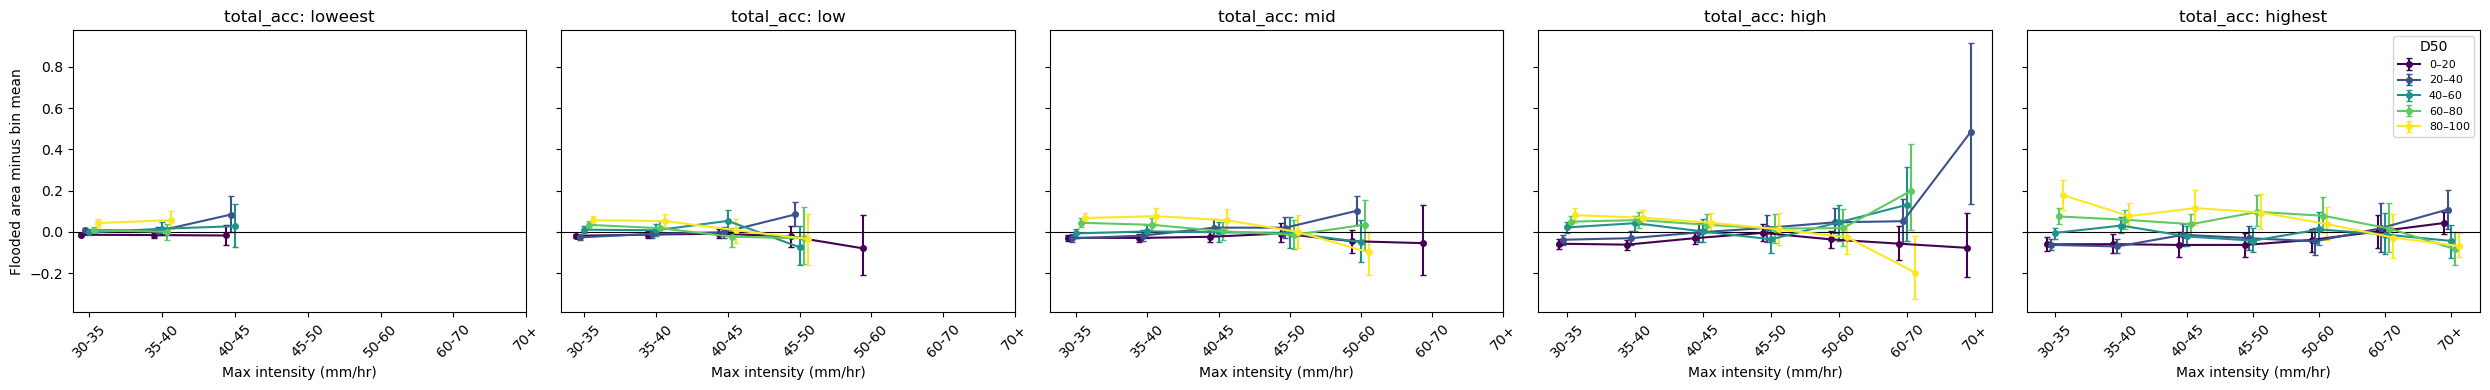

In [31]:
OUT, INT, D50 = "10cm_area", "max_precip", "d50_n"        # d50_n on a 0-100 scale
FACET = "total_acc"                                       # control variable to hold roughly fixed (try hc_class, capacity, length_of_active_rain)
MIN_N = 30

d = df.dropna(subset=[OUT, INT, D50, FACET]).copy()
d["int_bin"] = pd.cut(d[INT], INT_BINS, labels=INT_LAB, right=False)
d["d50_bin"] = pd.cut(d[D50], LOADING_BINS, labels=LOADING_LABELS, include_lowest=True)
d["facet"] = pd.qcut(d[FACET], 5, labels=["loweest", "low", "mid", "high", "highest"]) if d[FACET].nunique() > 6 else d[FACET].astype(str)

# print("Events per intensity bin x D50 class:\n", pd.crosstab(d["int_bin"], d["d50_bin"]))
# print(f"\nMean {FACET} by D50 class (is D50 confounded with {FACET}?):\n", d.groupby("d50_bin", observed=True)[FACET].mean().round(2))

rng = np.random.default_rng(0)
def ci(x, ref, n=500):
    b = [rng.choice(x, len(x)).mean() - ref for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

rows = []
for (f, ib), g in d.groupby(["facet", "int_bin"], observed=True):
    ref = g[OUT].mean()                                    # mean over all D50 classes in this cell
    for db, h in g.groupby("d50_bin", observed=True):
        if len(h) >= MIN_N:
            lo, hi = ci(h[OUT].values, ref)
            rows.append({"facet": f, "int_bin": ib, "d50_bin": db, "n": len(h), "dev": h[OUT].mean() - ref, "lo": lo, "hi": hi})
res = pd.DataFrame(rows)

facets = list(res["facet"].unique())
fig, axes = plt.subplots(1, len(facets), figsize=(5 * len(facets), 4), sharey=True)
axes = np.atleast_1d(axes)
cmap = plt.cm.viridis(np.linspace(0, 1, len(LOADING_LABELS)))
for ax, f in zip(axes, facets):
    for c, db in zip(cmap, LOADING_LABELS):
        s = res[(res.facet == f) & (res.d50_bin == db)].set_index("int_bin").reindex(INT_LAB)
        x = np.arange(len(INT_LAB)) + (LOADING_LABELS.index(db) - 2) * 0.06
        ax.errorbar(x, s["dev"], yerr=[s["dev"] - s["lo"], s["hi"] - s["dev"]], fmt="o-", color=c, ms=4, lw=1.5, capsize=2, label=db)
    ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB, rotation=45)
    ax.set_title(f"{FACET}: {f}"); ax.set_xlabel("Max intensity (mm/hr)")
axes[0].set_ylabel("Flooded area minus bin mean"); axes[-1].legend(title="D50", fontsize=8)
plt.tight_layout(); plt.show()

-------------

Similar idea: trying to understand whether late-D50 events flood more than early-D50 events with the same rainfall?  
Reports one number (% difference in flooded area) overall, and for 2 intensity bands x 2 capacity groups.

-------------

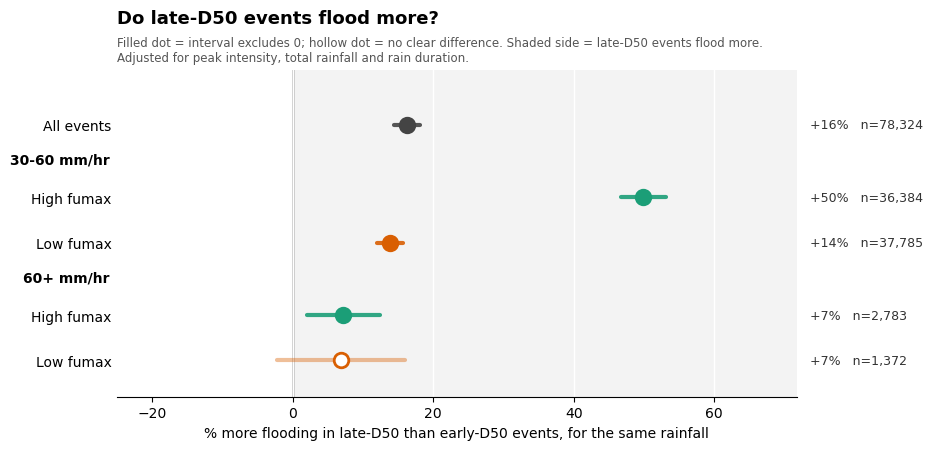

In [40]:
OUT, D50 = "10cm_area", "d50_n"                       # d50_n on a 0-100 scale
CONTROLS = ["max_precip", "total_acc"]
STATE, STATE_LABEL = "mean_sm_2_before_event", "SM"           # one cell-state variable to split on (edit)
STATE, STATE_LABEL = "fumax_at_peak", "fumax"           # one cell-state variable to split on (edit)
INT_SPLIT = 60                                        # mm/hr dividing 'lower' and 'higher' intensity
MIN_N = 300

d = df.dropna(subset=[OUT, D50, STATE] + CONTROLS).rename(columns={OUT: "y"})
d = d[(d[D50] < 33) | (d[D50] > 67)].copy()           # clearly early vs clearly late events
d["late"] = (d[D50] > 67).astype(int)
lo_lab, hi_lab = f"{int(d.max_precip.min())}-{INT_SPLIT} mm/hr", f"{INT_SPLIT}+ mm/hr"
d["intensity"] = np.where(d["max_precip"] < INT_SPLIT, lo_lab, hi_lab)
d["state"] = np.where(d[STATE] < d[STATE].median(), f"Low {STATE_LABEL}", f"High {STATE_LABEL}")

def late_vs_early(g):
    fit = smf.ols("y ~ late + " + " + ".join(CONTROLS), g).fit(cov_type="HC3")
    base = g.loc[g.late == 0, "y"].mean()
    lo, hi = fit.conf_int().loc["late"]
    return {"n": len(g), "pct": 100 * fit.params["late"] / base, "lo": 100 * lo / base, "hi": 100 * hi / base}

rows = [{"intensity": "All events", "state": "All", **late_vs_early(d)}]
for (i, s), g in d.groupby(["intensity", "state"]):
    if len(g) >= MIN_N and g.late.nunique() == 2:
        rows.append({"intensity": i, "state": s, **late_vs_early(g)})
res = pd.DataFrame(rows)
# print(res.round(1).to_string(index=False))

# ----------------------------------------------------------------------------------------------------------
# PLOT
# ----------------------------------------------------------------------------------------------------------
colours = {f"Low {STATE_LABEL}": "#d95f02", f"High {STATE_LABEL}": "#1b9e77", "All": "#444444"}
ypos, y = [], 0
for k, (i, g) in enumerate(res.groupby("intensity", sort=False)):
    if k > 0: y -= 0.6                                    # gap between groups
    for _ in range(len(g)):
        ypos.append(y); y -= 1
res["y"] = ypos

fig, ax = plt.subplots(figsize=(10, 4.8))
xmax = max(abs(res[["lo", "hi"]].values).max(), 5) * 1.35
ax.axvspan(0, xmax, color="#f3f3f3", zorder=0); ax.axvline(0, color="k", lw=1, zorder=1)
for _, r in res.iterrows():
    sig = (r.lo > 0) or (r.hi < 0)
    c = colours[r.state]
    ax.plot([r.lo, r.hi], [r.y, r.y], color=c, lw=3, alpha=0.9 if sig else 0.4, solid_capstyle="round", zorder=2)
    ax.scatter(r.pct, r.y, s=110, color=c if sig else "white", edgecolor=c, linewidth=2, zorder=3)
    ax.text(1.02, r.y, f"{r.pct:+.0f}%   n={int(r.n):,}", transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=9, color="#333")

labels = [("All events" if r.state == "All" else r.state) for _, r in res.iterrows()]
ax.set_yticks(res["y"]); ax.set_yticklabels(labels, fontsize=10)
for i, g in res.groupby("intensity", sort=False):                  # intensity-band headers
    if i != "All events":
        ax.text(-0.01, g["y"].max() + 0.75, i, transform=ax.get_yaxis_transform(), ha="right", fontsize=10, fontweight="bold")
ax.set_xlim(-xmax * 0.35, xmax); ax.set_ylim(res["y"].min() - 0.8, res["y"].max() + 1.2)
ax.set_xlabel("% more flooding in late-D50 than early-D50 events, for the same rainfall")
ax.set_title("Do late-D50 events flood more?", loc="left", fontsize=13, fontweight="bold", pad=34)
ax.text(0, 1.02, "Filled dot = interval excludes 0; hollow dot = no clear difference. Shaded side = late-D50 events flood more.\n"
        "Adjusted for peak intensity, total rainfall and rain duration.", transform=ax.transAxes, fontsize=8.5, color="#555", va="bottom")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0); ax.grid(axis="x", color="white", lw=1, zorder=1)
plt.subplots_adjust(left=0.18, right=0.86, top=0.82, bottom=0.14); plt.savefig("d50_comparison.png", dpi=200); plt.show()

###  How big is the D50 effect, and does it depend on peak intensity and on the state of the cell?  

For each (state group x intensity band) it fits   area ~ D50 + rainfall controls   and reports the D50 effect
as 'change in flooded area when D50 goes from early to late' (+SHIFT points), with a 95% interval.  
Shown as a heatmap (one number per cell) and a dot-and-whisker plot.  

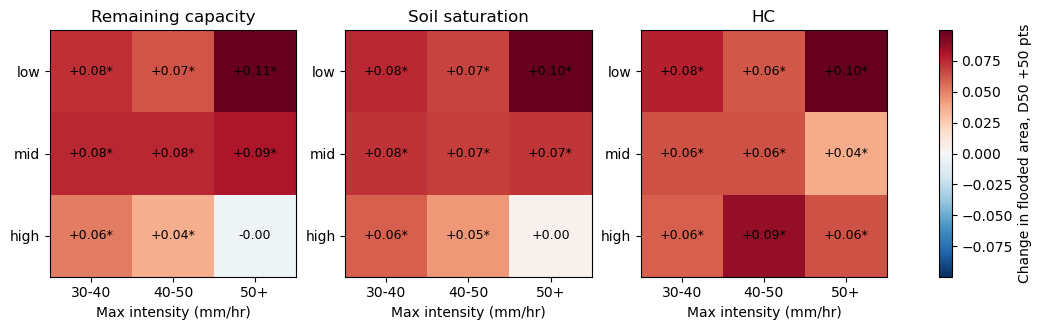

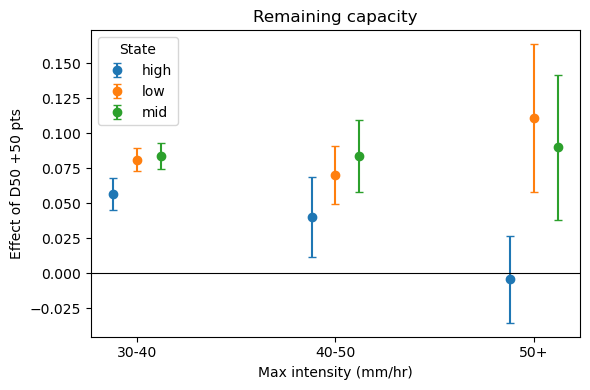

 grp  band     n  effect     lo    hi
high 30-40 23087   0.057  0.045 0.068
high 40-50  6717   0.040  0.012 0.069
high   50+  5388  -0.004 -0.036 0.027
 low 30-40 25200   0.081  0.073 0.089
 low 40-50  7010   0.070  0.049 0.091
 low   50+  2982   0.111  0.058 0.164
 mid 30-40 24900   0.084  0.074 0.093
 mid 40-50  6836   0.084  0.058 0.110
 mid   50+  3455   0.090  0.038 0.142


In [41]:

OUT, D50 = "10cm_area", "d50_n"                           # d50_n on a 0-100 scale
CONTROLS = ["max_precip", "total_acc", "length_of_active_rain"]
STATE_COLS = {"Remaining capacity": "sat_at_peak_old",           # edit: label -> column name (event-varying and/or static state variables)
              "Soil saturation": "sat_at_peak_new",
              "HC": "fumax_at_peak"}
INT_EDGES, INT_LAB = [30, 40, 50, np.inf], ["30-40", "40-50", "50+"]
MIN_N = 200
SHIFT = 50                                                # early (D50 ~25) -> late (D50 ~75)

def effect_table(d, state_col):
    d = d.rename(columns={OUT: "y"}).copy()
    if d[state_col].nunique() <= 5 or not np.issubdtype(d[state_col].dtype, np.number):
        d["grp"] = d[state_col].astype(str)                                       # already classes (e.g. HC class)
    else:
        d["grp"] = pd.qcut(d[state_col].rank(method="first"), 3, labels=["low", "mid", "high"]).astype(str)
    d["band"] = pd.cut(d["max_precip"], INT_EDGES, labels=INT_LAB, right=False)
    rows = []
    for (s, b), g in d.groupby(["grp", "band"], observed=True):
        if len(g) < MIN_N:
            continue
        fit = smf.ols(f"y ~ {D50} + {' + '.join(CONTROLS)}", data=g).fit(cov_type="HC3")
        lo, hi = fit.conf_int().loc[D50] * SHIFT
        rows.append({"grp": s, "band": b, "n": len(g), "effect": fit.params[D50] * SHIFT, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)

def plot_heatmap(t, title, ax):
    order = [g for g in ["low", "mid", "high"] if g in set(t.grp)] or sorted(t.grp.unique())
    piv = t.pivot(index="grp", columns="band", values="effect").reindex(index=order, columns=INT_LAB)
    sig = t.assign(s=(t.lo > 0) | (t.hi < 0)).pivot(index="grp", columns="band", values="s").reindex(index=order, columns=INT_LAB)
    lim = np.nanmax(np.abs(piv.values))
    im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:+.2f}" + ("*" if sig.values[i, j] == True else ""),
                    ha="center", va="center", fontsize=9, color="grey" if np.isnan(v) else "black")
    ax.set_title(title); ax.set_xlabel("Max intensity (mm/hr)")
    return im

d = df.dropna(subset=[OUT, D50] + CONTROLS + list(STATE_COLS.values())).copy()
tables = {lab: effect_table(d, col) for lab, col in STATE_COLS.items()}

# --- Plot 1: heatmaps. Red = late-D50 events flood MORE, blue = LESS; * = interval excludes 0; n/a = too few events ---
fig, axes = plt.subplots(1, len(tables), figsize=(4.5 * len(tables), 3.2), sharex=True)
for ax, (lab, t) in zip(np.atleast_1d(axes), tables.items()):
    im = plot_heatmap(t, lab, ax)
plt.colorbar(im, ax=axes, label=f"Change in flooded area, D50 +{SHIFT} pts"); plt.show()

# --- Plot 2: dot-and-whisker for one state variable ---
lab = list(STATE_COLS)[0]; t = tables[lab]
fig, ax = plt.subplots(figsize=(6, 4))
for k, (g, h) in enumerate(t.groupby("grp")):
    x = np.array([INT_LAB.index(b) for b in h["band"]]) + (k - 1) * 0.12
    ax.errorbar(x, h["effect"], yerr=[h["effect"] - h["lo"], h["hi"] - h["effect"]], fmt="o", capsize=3, label=g)
ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(len(INT_LAB))); ax.set_xticklabels(INT_LAB)
ax.set_xlabel("Max intensity (mm/hr)"); ax.set_ylabel(f"Effect of D50 +{SHIFT} pts"); ax.set_title(lab); ax.legend(title="State")
plt.tight_layout(); plt.show()
print(tables[lab].round(3).to_string(index=False))

## Find pairs of events with similar characteristics in match_vars
And then compare flooded area for early and late peaking events

In [44]:
profile = "d50_n"
target = "10cm_area"

match_vars = [
    "max_precip",
    "total_acc",
    "mean_sm_2_before_event",
    "hc_at_peak",
    "peak_cell_slope_avg",
    "peak_cell_urban_prop"
]

data = df[match_vars + [profile, target]].replace([np.inf, -np.inf], np.nan).dropna().copy()

# Define early- and late-peaking events
low, high = data[profile].quantile([0.25, 0.75])
early = data[data[profile] <= low].copy()
late = data[data[profile] >= high].copy()

# Standardise matching variables
scaler = StandardScaler()
scaler.fit(data[match_vars])
early_x = scaler.transform(early[match_vars])
late_x = scaler.transform(late[match_vars])

# Match each late event to the closest unused early event
distances = cdist(late_x, early_x)
pairs = []
used_early = set()

for i in range(len(late)):
    candidates = np.argsort(distances[i])
    best = next((j for j in candidates if j not in used_early), None)

    if best is None:
        continue

    pairs.append({
        "early_index": early.index[best],
        "late_index": late.index[i],
        "match_distance": distances[i, best],
        "early_area": early.iloc[best][target],
        "late_area": late.iloc[i][target],
        "area_difference": late.iloc[i][target] - early.iloc[best][target]
    })
    used_early.add(best)

matched = pd.DataFrame(pairs)

print(f"Matched pairs: {len(matched)}")
if len(matched):
    print(f"Mean difference (late - early): {matched['area_difference'].mean():.3f}")
    print(f"Median difference: {matched['area_difference'].median():.3f}")
    print(f"Proportion with greater flooding in late events: {(matched['area_difference'] > 0).mean():.1%}")

Matched pairs: 26394
Mean difference (late - early): 0.109
Median difference: 0.063
Proportion with greater flooding in late events: 64.4%
